# Polynomial Regression Using Different Optimization Algorithms

In [1]:
!pip install ucimlrepo

## 1. Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Loading

In [3]:
try:
    # Primary source: UCI (internet)
    auto_mpg = fetch_ucirepo(id=9)
    X_data = auto_mpg.data.features
    y_data = auto_mpg.data.targets

    df = X_data.copy()
    df["mpg"] = y_data["mpg"]

    print("Loaded from UCI (internet)")

except Exception as e:
    # Backup source: Kaggle Dataset
    print("UCI failed, loading Kaggle backup:", e)

    import os

    for root, dirs, files in os.walk("/kaggle/input"):
        if "auto-mpg.data" in files:
            backup_path = os.path.join(root, "auto-mpg.data")
            break

    df = pd.read_csv(
        backup_path,
        names=["mpg", "cylinders", "displacement", "horsepower",
               "weight", "acceleration", "model_year", "origin", "car_name"],
        na_values="?",
        sep=r"\s+",
        skipinitialspace=True
    )

df = df[["horsepower", "mpg"]]

df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df["mpg"] = pd.to_numeric(df["mpg"], errors="coerce")

display(df.head())
print("Dataset shape:", df.shape)

Loaded from UCI (internet)


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


Dataset shape: (398, 2)


## 3. Exploratory Data Analysis (EDA)

In [4]:
# Dataset Information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horsepower  392 non-null    float64
 1   mpg         398 non-null    float64
dtypes: float64(2)
memory usage: 6.3 KB

Statistical Summary:


,horsepower,mpg
count,392.000000,398.000000
mean,104.469388,23.514573
std,38.491160,7.815984
min,46.000000,9.000000
25%,75.000000,17.500000
50%,93.500000,23.000000
75%,126.000000,29.000000
max,230.000000,46.600000



Missing Values:
horsepower    6
mpg           0
dtype: int64


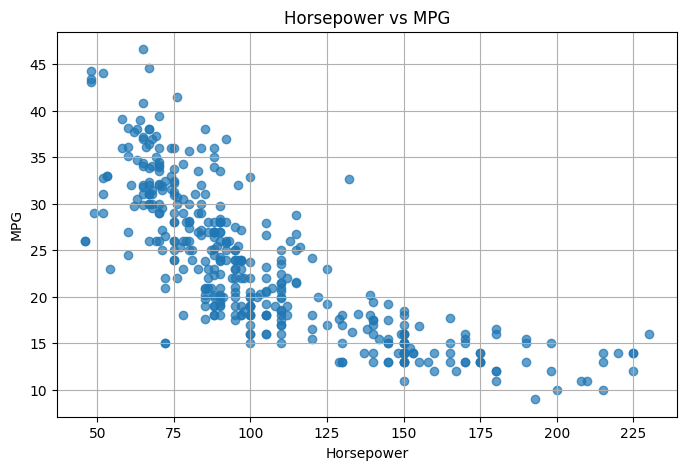

In [5]:

plt.figure(figsize=(8, 5))

plt.scatter(df["horsepower"], df["mpg"], alpha=0.7)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG")

plt.grid(True)
plt.show()


## 4. Data Preprocessing

4.1 Separate Features and Target

4.2 Split Data into Training and Testing Sets

4.3 Handle Missing Values

4.4 Polynomial Feature Transformation

4.5 Feature Scaling

4.6 Add Bias Term

In [6]:

X = df[["horsepower"]].values
y = df[["mpg"]].values

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (398, 1)
y shape: (398, 1)


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 318
Testing samples: 80


In [8]:

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Missing values handled successfully!")


Missing values handled successfully!


In [9]:

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original features:", X_train.shape)
print("Polynomial features:", X_train_poly.shape)

print("\nFirst 5 polynomial samples:")
print(X_train_poly[:5])


Original features: (318, 1)
Polynomial features: (318, 2)

First 5 polynomial samples:
[[  150. 22500.]
 [   88.  7744.]
 [   68.  4624.]
 [   60.  3600.]
 [   95.  9025.]]


In [10]:

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Scale the target values too
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print("Feature scaling completed!")


Feature scaling completed!


In [11]:

# Add bias column to training and testing data

X_train_model = np.c_[
    np.ones((X_train_scaled.shape[0], 1)),
    X_train_scaled
]

X_test_model = np.c_[
    np.ones((X_test_scaled.shape[0], 1)),
    X_test_scaled
]

print("Training shape:", X_train_model.shape)
print("Testing shape:", X_test_model.shape)


Training shape: (318, 3)
Testing shape: (80, 3)


## 5. Model and Loss Function

In [12]:

# Initialize model parameters

n_features = X_train_model.shape[1]

initial_weights = np.zeros((n_features, 1))

print("Initial weights:")
print(initial_weights)


Initial weights:
[[0.]
 [0.]
 [0.]]


In [13]:

def compute_loss(X, y, weights):

    predictions = X @ weights

    #Mean Squared Error (MSE)
    loss = np.mean((predictions - y) ** 2)

    return loss


## 6. Optimization Algorithm

6.1 Gradient Descent (GD)


In [14]:

def compute_gradient(X, y, weights):

    m = len(y)

    predictions = X @ weights

    gradient = (2 / m) * X.T @ (predictions - y)

    return gradient


## 7. Train the Model

In [15]:
def train_gd(learning_rate=0.05, epochs=2000,
             use_momentum=False, beta=0.9):

    weights = np.zeros((X_train_model.shape[1], 1))
    velocity = np.zeros_like(weights)

    loss_history = []

    start_time = time.time()

    for epoch in range(epochs):

        gradient = compute_gradient(
            X_train_model,
            y_train_scaled,
            weights
        )

        if use_momentum:
            velocity = beta * velocity + gradient
            weights -= learning_rate * velocity

        else:
            weights -= learning_rate * gradient

        epoch_loss = compute_loss(
            X_train_model,
            y_train_scaled,
            weights
        )

        loss_history.append(epoch_loss)

    training_time = time.time() - start_time

    return weights, loss_history, training_time

In [16]:
# 1. GD without Momentum
weights_gd, loss_history_gd, training_time_gd = train_gd(
    use_momentum=False
)

# 2. GD with Momentum
weights_momentum, loss_history_momentum, training_time_momentum = train_gd(
    use_momentum=True
)

# Print Results
print("GD Final Loss:", loss_history_gd[-1])
print("GD Training Time:", training_time_gd)
print("GD Final Weights:")
print(weights_gd)

print("\nGD + Momentum Final Loss:", loss_history_momentum[-1])
print("GD + Momentum Training Time:", training_time_momentum)
print("GD + Momentum Final Weights:")
print(weights_momentum)

GD Final Loss: 0.33685994288910465
GD Training Time: 0.09976506233215332
GD Final Weights:
[[-2.57357070e-16]
 [-2.15906715e+00]
 [ 1.41765718e+00]]

GD + Momentum Final Loss: 0.3367472533819561
GD + Momentum Training Time: 0.06146979331970215
GD + Momentum Final Weights:
[[-2.78892528e-16]
 [-2.21601070e+00]
 [ 1.47460073e+00]]


## 8. Visualizing Training Loss

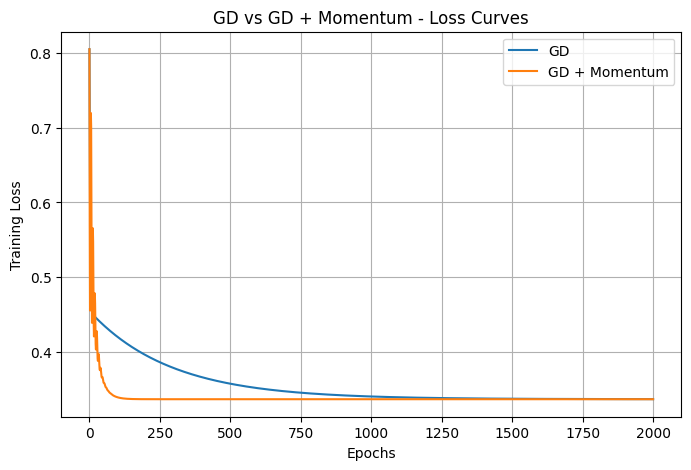

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history_gd, label="GD")
plt.plot(loss_history_momentum, label="GD + Momentum")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("GD vs GD + Momentum - Loss Curves")

plt.legend()
plt.grid(True)
plt.show()

## 9. Model Evaluation

In [18]:
# Predictions using GD
y_pred_gd_scaled = X_test_model @ weights_gd

# Predictions using GD + Momentum
y_pred_momentum_scaled = X_test_model @ weights_momentum

# Convert predictions back to original MPG scale
y_pred_gd = scaler_y.inverse_transform(y_pred_gd_scaled)
y_pred_momentum = scaler_y.inverse_transform(y_pred_momentum_scaled)

# Evaluate GD
print("GD Evaluation:")
print("MSE:", mean_squared_error(y_test, y_pred_gd))
print("MAE:", mean_absolute_error(y_test, y_pred_gd))
print("R2 Score:", r2_score(y_test, y_pred_gd))

# Evaluate GD + Momentum
print("\nGD + Momentum Evaluation:")
print("MSE:", mean_squared_error(y_test, y_pred_momentum))
print("MAE:", mean_absolute_error(y_test, y_pred_momentum))
print("R2 Score:", r2_score(y_test, y_pred_momentum))

GD Evaluation:
MSE: 13.932684927958343
MAE: 2.9289756040546004
R2 Score: 0.7408665339158061

GD + Momentum Evaluation:
MSE: 13.978713313447921
MAE: 2.9249013008213565
R2 Score: 0.740010453760987


## 10. Compare Results

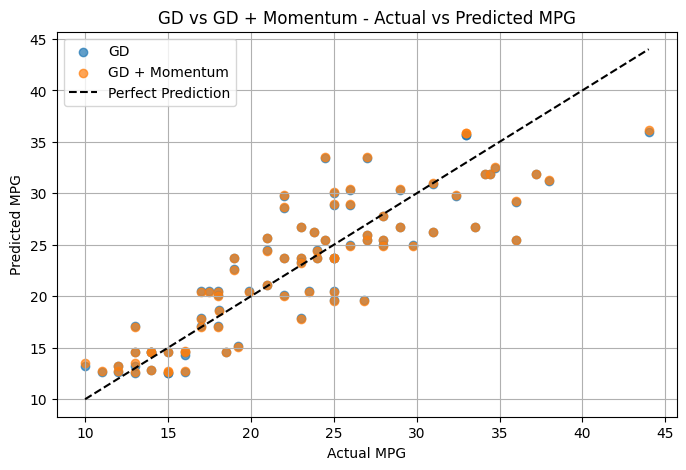

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_gd, label="GD", alpha=0.7)
plt.scatter(y_test, y_pred_momentum, label="GD + Momentum", alpha=0.7)

# Perfect prediction line
min_value = y_test.min()
max_value = y_test.max()

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'k--',
    label="Perfect Prediction"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("GD vs GD + Momentum - Actual vs Predicted MPG")
plt.legend()
plt.grid(True)
plt.show()

## Conclusion

In this notebook, Polynomial Regression (degree 2) was implemented using Gradient Descent to predict fuel efficiency (MPG) from horsepower. Missing values were imputed with the training median, and features and target were standardized so the optimizers work on a well-scaled problem.

Two experiments were conducted: Gradient Descent without Momentum and with Momentum (learning rate 0.05, 2000 epochs). Plain GD converges slowly here because horsepower and horsepower² are strongly correlated (an ill-conditioned problem), so it needs many more epochs than the momentum version to reach the same loss; with only 500 epochs it had not converged. Momentum accelerates convergence along the shallow direction of the loss surface.

Both models were evaluated with MSE, MAE and R² on the test set, and the loss curves and actual-vs-predicted plots were used to compare them. Re-run the notebook to see the final numbers: once both runs have converged, their test metrics should be nearly identical, which shows the difference between them is mainly about speed of convergence, not final quality.